In [15]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt

In [ ]:
path = "file_path"

transform = transforms.ToTensor()

train_data = datasets.FashionMNIST(
    root=path,
    train=True,
    download=False,
    transform=transform
)

test_data = datasets.FashionMNIST(
    root=path,
    train=False,
    download=False,
    transform=transform
)

train_loader = DataLoader(
    train_data,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_data,
    batch_size=64,
    shuffle=False
)

print("Dataset loaded successfully")

Dataset loaded successfully


In [17]:
class MLP(nn.Module):

    def __init__(self, hidden_layers=[128], activation=nn.ReLU):
        super().__init__()

        layers = [nn.Flatten()]

        in_features = 784

        for neurons in hidden_layers:

            layers.append(nn.Linear(in_features, neurons))
            layers.append(activation())

            in_features = neurons

        layers.append(nn.Linear(in_features, 10))

        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

In [18]:
def train_model(hidden_layers, activation):

    model = MLP(hidden_layers, activation)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001
    )

    train_loss = []
    train_acc = []

    epochs = 10

    for epoch in range(epochs):

        model.train()

        running_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss.append(running_loss / len(train_loader))

        train_acc.append(100 * correct / total)

        print(
            f"Epoch {epoch+1}, Loss: {train_loss[-1]:.4f}, "
            f"Accuracy: {train_acc[-1]:.2f}%"
        )

    # Testing

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in test_loader:

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total

    return model, accuracy, train_loss, train_acc

In [19]:
configs = {
    "ReLU": nn.ReLU,
    "Tanh": nn.Tanh,
    "Sigmoid": nn.Sigmoid
}

hidden_layers = [128]

results = {}

for name, activation in configs.items():

    print("\nTraining:", name)

    model, accuracy, loss, acc = train_model(
        hidden_layers, activation
    )

    results[name] = {
        "accuracy": accuracy,
        "loss": loss,
        "train_acc": acc
    }

    print("Test Accuracy:", accuracy)


Training: ReLU
Epoch 1, Loss: 0.5516, Accuracy: 80.97%
Epoch 2, Loss: 0.4040, Accuracy: 85.66%
Epoch 3, Loss: 0.3649, Accuracy: 86.76%
Epoch 4, Loss: 0.3398, Accuracy: 87.67%
Epoch 5, Loss: 0.3203, Accuracy: 88.38%
Epoch 6, Loss: 0.3034, Accuracy: 88.89%
Epoch 7, Loss: 0.2904, Accuracy: 89.40%
Epoch 8, Loss: 0.2796, Accuracy: 89.80%
Epoch 9, Loss: 0.2720, Accuracy: 89.92%
Epoch 10, Loss: 0.2612, Accuracy: 90.32%
Test Accuracy: 88.21

Training: Tanh
Epoch 1, Loss: 0.5154, Accuracy: 81.81%
Epoch 2, Loss: 0.3808, Accuracy: 86.26%
Epoch 3, Loss: 0.3465, Accuracy: 87.45%
Epoch 4, Loss: 0.3204, Accuracy: 88.22%
Epoch 5, Loss: 0.3032, Accuracy: 88.89%
Epoch 6, Loss: 0.2901, Accuracy: 89.29%
Epoch 7, Loss: 0.2773, Accuracy: 89.70%
Epoch 8, Loss: 0.2677, Accuracy: 90.09%
Epoch 9, Loss: 0.2574, Accuracy: 90.42%
Epoch 10, Loss: 0.2479, Accuracy: 90.80%
Test Accuracy: 87.93

Training: Sigmoid
Epoch 1, Loss: 0.6459, Accuracy: 78.78%
Epoch 2, Loss: 0.4112, Accuracy: 85.38%
Epoch 3, Loss: 0.3721, Ac

In [20]:
for name, result in results.items():

    print(
        name,
        "Accuracy:",
        f"{result['accuracy']:.2f}%"
    )

ReLU Accuracy: 88.21%
Tanh Accuracy: 87.93%
Sigmoid Accuracy: 87.62%


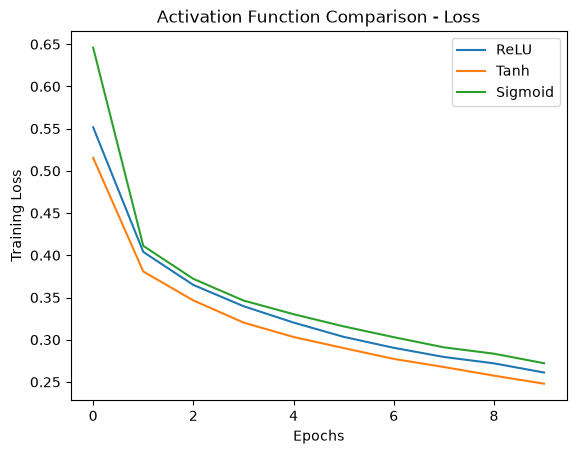

In [21]:
for name, result in results.items():

    plt.plot(result["loss"], label=name)

plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.title("Activation Function Comparison - Loss")

plt.legend()
plt.show()

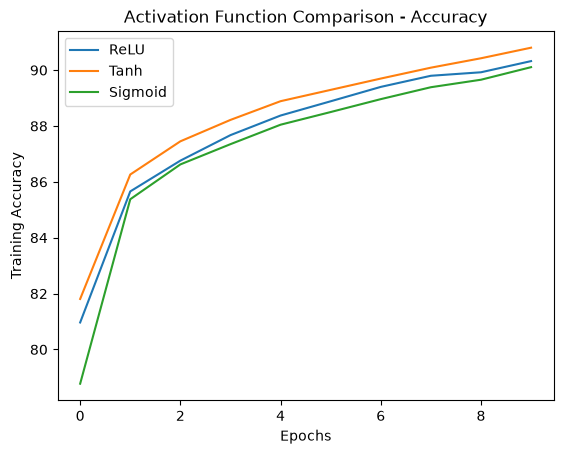

In [22]:
for name, result in results.items():

    plt.plot(result["train_acc"], label=name)

plt.xlabel("Epochs")
plt.ylabel("Training Accuracy")
plt.title("Activation Function Comparison - Accuracy")

plt.legend()
plt.show()